# Weinreb multilineage metaclones: composition and branch-resolved dynamics

This notebook addresses the requested comparison of MC0, MC2, MC5, MC3, and
MC18 at Days 4 and 6 in the current 9,714-cell Weinreb/Palantir object.

The primary composition estimand is the mean within-clone fine-state
composition for each metaclone and day, so every observed clone contributes
equally. A pooled-cell composition table is retained as a sensitivity analysis.
Branch panels show sampled-cell density along global Palantir pseudotime among
cells passing each hard Baso, Neu, or Mono branch mask. The masks overlap; they
describe branch compatibility rather than mutually exclusive fate assignment.
Clone medians are overlaid, and any inferential test uses clones rather than
cells as the independent units.

In [1]:
# Environment and execution manifest
from pathlib import Path
import hashlib
import importlib.metadata as im
import platform
import sys

import anndata as ad
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.spatial.distance import jensenshannon
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

matplotlib.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none",
})

PROJECT_ROOT = Path("/path/to/ChronoClone")
ANALYSIS_DIR = PROJECT_ROOT / "analysis_workspace/analyses/weinreb_multilineage_metaclone_dynamics_20260901"
FIGURE_DIR = ANALYSIS_DIR / "figures"
TABLE_DIR = ANALYSIS_DIR / "tables"
REPORT_DIR = ANALYSIS_DIR / "reports"
INPUT_PATH = PROJECT_ROOT / "reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad"
NOTEBOOK_PATH = ANALYSIS_DIR / "0001_weinreb_multilineage_metaclone_dynamics.ipynb"
ENV_PATH = Path("/path/to/ChronoClone/.runtime/chronoclone")
EXECUTION_COMMAND = (
    f"{ENV_PATH}/bin/python -m jupyter nbconvert --to notebook --execute --inplace "
    f"--ExecutePreprocessor.kernel_name=chronoclone "
    f"--ExecutePreprocessor.timeout=1200 {NOTEBOOK_PATH}"
)

for path in (FIGURE_DIR, TABLE_DIR, REPORT_DIR):
    path.mkdir(parents=True, exist_ok=True)

print("Environment manager: reused existing Conda-compatible environment; no mutation")
print("Environment name: chronoclone")
print(f"Absolute environment path: {ENV_PATH}")
print("Kernel: chronoclone")
print(f"Python: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"anndata: {im.version('anndata')}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
print(f"scipy: {scipy.__version__}")
print(f"matplotlib: {matplotlib.__version__}")
print(f"Notebook: {NOTEBOOK_PATH}")
print(f"Execution command: {EXECUTION_COMMAND}")

Environment manager: reused existing Conda-compatible environment; no mutation
Environment name: chronoclone
Absolute environment path: /path/to/ChronoClone/.runtime/chronoclone
Kernel: chronoclone
Python: 3.11.15
Platform: macOS-26.6.2-arm64-arm-64bit
anndata: 0.12.18
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.0
Notebook: /path/to/ChronoClone/analysis_workspace/analyses/weinreb_multilineage_metaclone_dynamics_20260901/0001_weinreb_multilineage_metaclone_dynamics.ipynb
Execution command: /path/to/ChronoClone/.runtime/chronoclone/bin/python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone --ExecutePreprocessor.timeout=1200 /path/to/ChronoClone/analysis_workspace/analyses/weinreb_multilineage_metaclone_dynamics_20260901/0001_weinreb_multilineage_metaclone_dynamics.ipynb


## Estimands and interpretation

- Composition: fine annotated state fractions at Day 4 or Day 6, averaged
  across clones within a metaclone. This includes progenitors and mature cells.
- Pooled-cell sensitivity: the ordinary fraction of sampled cells in each fine
  state for the same metaclone and day.
- Branch occupancy: fraction of cells passing each hard branch mask. These
  fractions are not compositional because masks can overlap.
- Branch position: global Palantir pseudotime among cells passing a branch mask.
  Violin widths are descriptive cell-density estimates. Clone medians are the
  independent-unit summaries used for tests.

The analysis does not interpret absent clones at Day 6 as biological
disappearance, because destructive sampling and incomplete recovery can also
produce absence.

In [2]:
# Load the registered current object read-only and lock provenance
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

input_sha256 = sha256_file(INPUT_PATH)
adata = ad.read_h5ad(INPUT_PATH, backed="r")
obs = adata.obs.copy()
object_shape = adata.shape
cell_type_order = list(obs["cell_type"].cat.categories)
cell_type_colors = dict(zip(cell_type_order, adata.uns["cell_type_colors"]))
adata.file.close()

required_columns = [
    "day", "cell_type", "cell_type_weinreb", "LARRY_ID", "metaclone",
    "palantir_pseudotime", "mask_Baso", "mask_Neu", "mask_Mono"
]
missing_columns = [column for column in required_columns if column not in obs.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"
assert object_shape == (9714, 25289), object_shape
assert input_sha256 == "4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911"

print(f"Input: {INPUT_PATH}")
print(f"SHA256: {input_sha256}")
print(f"Shape: {object_shape}")
print(f"Required columns present: {len(required_columns)}")
print("Days:", sorted(obs["day"].unique().tolist()))
print("Fine cell states:", len(cell_type_order))

Input: /path/to/ChronoClone/reference_workspace/data/klein_metaclone_palantir_trajectories.h5ad
SHA256: 4cb08c12dc70f5c3789a75a09a6399db06b3f6efe18147b9f2cca0908ba93911
Shape: (9714, 25289)
Required columns present: 9
Days: [2, 4, 6]
Fine cell states: 21


In [3]:
# Lock the target cohort and save cell-level analysis metadata
TARGET_MCS = [0, 2, 5, 3, 18]
TARGET_DAYS = [4, 6]
BRANCHES = ["Baso", "Neu", "Mono"]
MC_COLORS = {
    0: "#f77189", 1: "#f7754f", 2: "#dc8932", 3: "#c39532",
    4: "#ae9d31", 5: "#97a431", 6: "#77ab31", 7: "#31b33e",
    8: "#33b07a", 9: "#35ae93", 10: "#36ada4", 11: "#37abb4",
    12: "#38a9c5", 13: "#3aa5df", 14: "#6e9bf4", 16: "#a48cf4",
    17: "#cc7af4", 18: "#f45cf2", 22: "#f565cc", 23: "#f66bad",
}

analysis_cells = obs.loc[
    obs["metaclone"].isin(TARGET_MCS) & obs["day"].isin(TARGET_DAYS),
    required_columns,
].copy()
analysis_cells["metaclone"] = analysis_cells["metaclone"].astype(int)
analysis_cells["day"] = analysis_cells["day"].astype(int)
analysis_cells["cell_type"] = analysis_cells["cell_type"].astype(str)
analysis_cells["cell_type_weinreb"] = analysis_cells["cell_type_weinreb"].astype(str)
for branch in BRANCHES:
    analysis_cells[f"mask_{branch}"] = analysis_cells[f"mask_{branch}"].astype(bool)
analysis_cells.index.name = "cell"

support = (
    analysis_cells.groupby(["metaclone", "day"], observed=True)
    .agg(n_cells=("LARRY_ID", "size"), n_clones=("LARRY_ID", "nunique"))
    .reindex(pd.MultiIndex.from_product([TARGET_MCS, TARGET_DAYS], names=["metaclone", "day"]))
    .reset_index()
)
assert support["n_cells"].notna().all()
assert support["n_clones"].notna().all()

analysis_cells.reset_index().to_csv(TABLE_DIR / "analysis_cell_metadata.csv", index=False)
support.to_csv(TABLE_DIR / "target_metaclone_day_support.csv", index=False)
display(support)

,metaclone,day,n_cells,n_clones
0,0,4,391,35
1,0,6,778,35
2,2,4,58,20
3,2,6,68,12
4,5,4,125,25
5,5,6,203,25
6,3,4,253,50
7,3,6,683,47
8,18,4,88,38
9,18,6,355,33


In [4]:
# Compute clone-balanced and pooled-cell fine-state composition
fine_order_present = [
    state for state in cell_type_order if state in set(analysis_cells["cell_type"])
]

clone_counts = (
    analysis_cells.groupby(["metaclone", "day", "LARRY_ID", "cell_type"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
clone_totals = (
    clone_counts.groupby(["metaclone", "day", "LARRY_ID"], observed=True)["n_cells"]
    .sum()
    .rename("clone_total")
    .reset_index()
)
clone_composition = clone_counts.merge(
    clone_totals, on=["metaclone", "day", "LARRY_ID"], validate="many_to_one"
)
clone_composition["fraction"] = (
    clone_composition["n_cells"] / clone_composition["clone_total"]
)
clone_complete_index = pd.MultiIndex.from_product(
    [
        TARGET_MCS,
        TARGET_DAYS,
        sorted(analysis_cells["LARRY_ID"].unique()),
        fine_order_present,
    ],
    names=["metaclone", "day", "LARRY_ID", "cell_type"],
)
# Only retain clone IDs that actually occur in each metaclone/day.
observed_clone_index = (
    analysis_cells[["metaclone", "day", "LARRY_ID"]]
    .drop_duplicates()
    .assign(_key=1)
    .merge(pd.DataFrame({"cell_type": fine_order_present, "_key": 1}), on="_key")
    .drop(columns="_key")
)
clone_complete = observed_clone_index.merge(
    clone_composition[["metaclone", "day", "LARRY_ID", "cell_type", "fraction"]],
    on=["metaclone", "day", "LARRY_ID", "cell_type"],
    how="left",
)
clone_complete["fraction"] = clone_complete["fraction"].fillna(0.0)

clone_balanced_composition = (
    clone_complete.groupby(["metaclone", "day", "cell_type"], observed=True)["fraction"]
    .mean()
    .rename("fraction")
    .reset_index()
)
pooled_cell_composition = (
    analysis_cells.groupby(["metaclone", "day", "cell_type"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
pooled_cell_composition["fraction"] = pooled_cell_composition.groupby(
    ["metaclone", "day"], observed=True
)["n_cells"].transform(lambda values: values / values.sum())

clone_balanced_composition.to_csv(
    TABLE_DIR / "fine_state_composition_clone_balanced.csv", index=False
)
pooled_cell_composition.to_csv(
    TABLE_DIR / "fine_state_composition_pooled_cells.csv", index=False
)

clone_sums = clone_balanced_composition.groupby(
    ["metaclone", "day"], observed=True
)["fraction"].sum()
pooled_sums = pooled_cell_composition.groupby(
    ["metaclone", "day"], observed=True
)["fraction"].sum()
assert np.allclose(clone_sums.values, 1.0)
assert np.allclose(pooled_sums.values, 1.0)
print("Clone-balanced composition rows:", len(clone_balanced_composition))
print("Pooled-cell sensitivity rows:", len(pooled_cell_composition))
print("Maximum absolute composition sum error:",
      max(float((clone_sums - 1).abs().max()), float((pooled_sums - 1).abs().max())))

Clone-balanced composition rows: 190
Pooled-cell sensitivity rows: 113
Maximum absolute composition sum error: 0.0


In [5]:
# Quantify pairwise fine-state composition similarity with Jensen-Shannon distance
def composition_matrix(table):
    return (
        table.pivot_table(
            index=["metaclone", "day"],
            columns="cell_type",
            values="fraction",
            fill_value=0.0,
            observed=True,
        )
        .reindex(columns=fine_order_present, fill_value=0.0)
        .sort_index()
    )

composition_distances = []
for estimand, table in [
    ("clone_balanced", clone_balanced_composition),
    ("pooled_cells", pooled_cell_composition),
]:
    matrix = composition_matrix(table)
    for day in TARGET_DAYS:
        for left_index, left_mc in enumerate(TARGET_MCS):
            for right_mc in TARGET_MCS[left_index + 1:]:
                distance = jensenshannon(
                    matrix.loc[(left_mc, day)].values,
                    matrix.loc[(right_mc, day)].values,
                    base=2,
                )
                composition_distances.append(
                    {
                        "estimand": estimand,
                        "day": day,
                        "mc_a": left_mc,
                        "mc_b": right_mc,
                        "jensen_shannon_distance": float(distance),
                    }
                )

composition_distances = pd.DataFrame(composition_distances)
composition_distances.to_csv(
    TABLE_DIR / "fine_state_pairwise_jensen_shannon_distances.csv", index=False
)
display(
    composition_distances[
        composition_distances.apply(
            lambda row: {int(row["mc_a"]), int(row["mc_b"])}
            in [{3, 18}, {3, 5}],
            axis=1,
        )
    ].sort_values(["mc_a", "mc_b", "estimand", "day"])
)

,estimand,day,mc_a,mc_b,jensen_shannon_distance
9,clone_balanced,4,3,18,0.434846
19,clone_balanced,6,3,18,0.582764
29,pooled_cells,4,3,18,0.435091
39,pooled_cells,6,3,18,0.492010
7,clone_balanced,4,5,3,0.408365
17,clone_balanced,6,5,3,0.428881
27,pooled_cells,4,5,3,0.332945
37,pooled_cells,6,5,3,0.276247


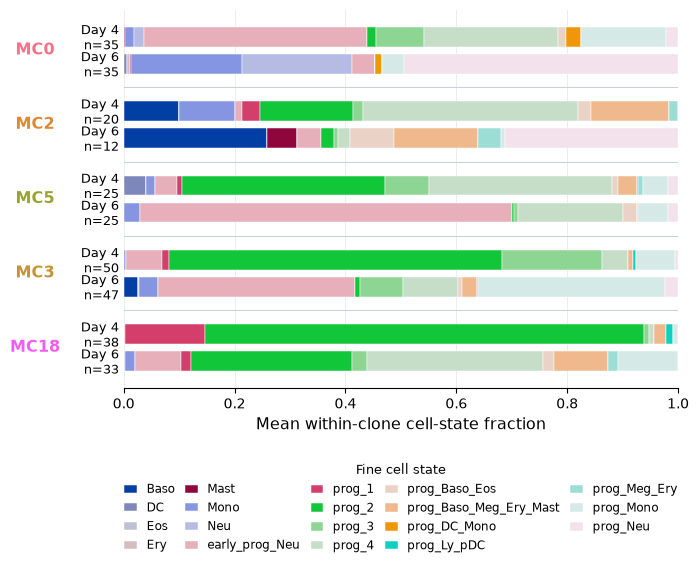

In [6]:
# Plot 1: clone-balanced fine-state composition at Days 4 and 6
plot_counts = (
    analysis_cells.groupby(["metaclone", "day", "LARRY_ID", "cell_type"], observed=True)
    .size()
    .rename("n_cells")
    .reset_index()
)
plot_counts["clone_total"] = plot_counts.groupby(
    ["metaclone", "day", "LARRY_ID"], observed=True
)["n_cells"].transform("sum")
plot_counts["within_clone_fraction"] = (
    plot_counts["n_cells"] / plot_counts["clone_total"]
)
plot_clone_state_grid = (
    analysis_cells[["metaclone", "day", "LARRY_ID"]]
    .drop_duplicates()
    .assign(_key=1)
    .merge(pd.DataFrame({"cell_type": fine_order_present, "_key": 1}), on="_key")
    .drop(columns="_key")
)
plot_clone_state_grid = plot_clone_state_grid.merge(
    plot_counts[
        [
            "metaclone",
            "day",
            "LARRY_ID",
            "cell_type",
            "within_clone_fraction",
        ]
    ],
    on=["metaclone", "day", "LARRY_ID", "cell_type"],
    how="left",
)
plot_clone_state_grid["within_clone_fraction"] = (
    plot_clone_state_grid["within_clone_fraction"].fillna(0.0)
)
plot_table = (
    plot_clone_state_grid.groupby(
        ["metaclone", "day", "cell_type"], observed=True
    )[
        "within_clone_fraction"
    ]
    .mean()
    .rename("fraction")
    .reset_index()
)
plot_matrix = (
    plot_table.pivot_table(
        index=["day", "metaclone"],
        columns="cell_type",
        values="fraction",
        fill_value=0.0,
        observed=True,
    )
    .reindex(
        pd.MultiIndex.from_tuples(
            [(day, mc) for mc in TARGET_MCS for day in TARGET_DAYS],
            names=["day", "metaclone"],
        )
    )
    .reindex(columns=fine_order_present, fill_value=0.0)
)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
y_positions = np.array([12.5, 11.5, 9.75, 8.75, 7.0, 6.0, 4.25, 3.25, 1.5, 0.5])
left = np.zeros(len(plot_matrix))
for state in fine_order_present:
    values = plot_matrix[state].to_numpy()
    if np.allclose(values, 0):
        continue
    ax.barh(
        y_positions,
        values,
        left=left,
        height=0.72,
        color=cell_type_colors[state],
        edgecolor="white",
        linewidth=0.35,
        label=state,
    )
    left += values

support_lookup = support.set_index(["day", "metaclone"])["n_clones"]
labels = [
    f"Day {day}\nn={int(support_lookup.loc[(day, mc)])}"
    for mc in TARGET_MCS
    for day in TARGET_DAYS
]
ax.set_yticks(y_positions)
ax.set_yticklabels(labels, fontsize=9.4, linespacing=1.05)
ax.set_xlim(0, 1)
ax.set_xlabel("Mean within-clone cell-state fraction", fontsize=11.2)
for mc_index, mc in enumerate(TARGET_MCS):
    pair_midpoint = float(np.mean(y_positions[2 * mc_index: 2 * mc_index + 2]))
    ax.text(
        -0.16,
        pair_midpoint,
        f"MC{mc}",
        transform=ax.get_yaxis_transform(),
        ha="center",
        va="center",
        fontsize=11.5,
        fontweight="bold",
        color=MC_COLORS[mc],
    )
    if mc_index < len(TARGET_MCS) - 1:
        separator = (
            y_positions[2 * mc_index + 1] + y_positions[2 * mc_index + 2]
        ) / 2
        ax.axhline(separator, color="#CBD0D8", linewidth=0.75)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    legend_labels,
    title="Fine cell state",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    frameon=False,
    fontsize=8.4,
    title_fontsize=9.4,
    ncol=5,
    handlelength=1.1,
    columnspacing=0.9,
)
fig.subplots_adjust(left=0.22, right=0.99, bottom=0.37, top=0.98)
composition_stem = FIGURE_DIR / "weinreb_multilineage_fine_state_composition_day4_day6"
fig.savefig(composition_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(composition_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
plt.show()

In [7]:
# Compute branch occupancy, branch-pseudotime support, and clone-level tests
branch_occupancy_rows = []
branch_support_rows = []
clone_median_rows = []
for branch in BRANCHES:
    mask_column = f"mask_{branch}"
    for (mc, day), group in analysis_cells.groupby(["metaclone", "day"], observed=True):
        branch_cells = group[group[mask_column]]
        branch_occupancy_rows.append(
            {
                "estimand": "pooled_cells",
                "branch": branch,
                "metaclone": int(mc),
                "day": int(day),
                "occupancy_fraction": float(group[mask_column].mean()),
            }
        )
        clone_occupancy = group.groupby("LARRY_ID", observed=True)[mask_column].mean()
        branch_occupancy_rows.append(
            {
                "estimand": "clone_balanced",
                "branch": branch,
                "metaclone": int(mc),
                "day": int(day),
                "occupancy_fraction": float(clone_occupancy.mean()),
            }
        )
        branch_support_rows.append(
            {
                "branch": branch,
                "metaclone": int(mc),
                "day": int(day),
                "n_cells": int(len(branch_cells)),
                "n_clones": int(branch_cells["LARRY_ID"].nunique()),
                "fraction_of_all_mc_day_cells": float(group[mask_column].mean()),
                "median_pseudotime": float(branch_cells["palantir_pseudotime"].median())
                if len(branch_cells) else np.nan,
                "q25_pseudotime": float(branch_cells["palantir_pseudotime"].quantile(0.25))
                if len(branch_cells) else np.nan,
                "q75_pseudotime": float(branch_cells["palantir_pseudotime"].quantile(0.75))
                if len(branch_cells) else np.nan,
            }
        )
        per_clone = (
            branch_cells.groupby("LARRY_ID", observed=True)["palantir_pseudotime"]
            .median()
            .rename("clone_median_pseudotime")
            .reset_index()
        )
        per_clone["branch"] = branch
        per_clone["metaclone"] = int(mc)
        per_clone["day"] = int(day)
        clone_median_rows.append(per_clone)

branch_occupancy = pd.DataFrame(branch_occupancy_rows)
branch_support = pd.DataFrame(branch_support_rows)
clone_medians = pd.concat(clone_median_rows, ignore_index=True)

branch_tests = []
for (branch, day), group in clone_medians.groupby(["branch", "day"], observed=True):
    samples = [
        values["clone_median_pseudotime"].to_numpy()
        for _, values in group.groupby("metaclone", observed=True)
        if len(values) >= 3
    ]
    statistic, p_value = kruskal(*samples) if len(samples) >= 2 else (np.nan, np.nan)
    branch_tests.append(
        {
            "branch": branch,
            "day": int(day),
            "kruskal_H": float(statistic),
            "p_value": float(p_value),
            "n_metaclones_tested": len(samples),
            "independent_unit": "clone median",
        }
    )
branch_tests = pd.DataFrame(branch_tests)
valid_tests = branch_tests["p_value"].notna()
branch_tests.loc[valid_tests, "fdr_bh"] = multipletests(
    branch_tests.loc[valid_tests, "p_value"], method="fdr_bh"
)[1]

branch_occupancy.to_csv(TABLE_DIR / "branch_occupancy_fractions.csv", index=False)
branch_support.to_csv(TABLE_DIR / "branch_pseudotime_support.csv", index=False)
clone_medians.to_csv(TABLE_DIR / "branch_clone_median_pseudotime.csv", index=False)
branch_tests.to_csv(TABLE_DIR / "branch_clone_median_kruskal_tests.csv", index=False)
display(branch_support.sort_values(["branch", "day", "metaclone"]))
display(branch_tests.sort_values(["branch", "day"]))

,branch,metaclone,day,n_cells,n_clones,fraction_of_all_mc_day_cells,median_pseudotime,q25_pseudotime,q75_pseudotime
0,Baso,0,4,1,1,0.002558,0.755864,0.755864,0.755864
2,Baso,2,4,16,9,0.275862,0.478394,0.176808,0.757333
4,Baso,3,4,26,16,0.102767,0.110687,0.092547,0.126960
6,Baso,5,4,5,4,0.040000,0.178070,0.142829,0.394915
8,Baso,18,4,41,25,0.465909,0.104512,0.094313,0.121279
1,Baso,0,6,3,2,0.003856,0.866629,0.859247,0.875126
3,Baso,2,6,34,7,0.500000,0.689954,0.615603,0.808829
5,Baso,3,6,27,8,0.039531,0.770915,0.480241,0.853008
7,Baso,5,6,4,3,0.019704,0.622327,0.468515,0.751227
9,Baso,18,6,55,12,0.154930,0.259082,0.114594,0.595731


,branch,day,kruskal_H,p_value,n_metaclones_tested,independent_unit,fdr_bh
0,Baso,4,15.799934,1.246265e-03,4,clone median,1.495518e-03
1,Baso,6,12.023502,7.303084e-03,4,clone median,7.303084e-03
2,Mono,4,54.508937,4.117389e-11,5,clone median,8.234777e-11
3,Mono,6,41.972904,4.065599e-09,4,clone median,6.098399e-09
4,Neu,4,90.346186,1.111640e-18,5,clone median,3.334919e-18
5,Neu,6,96.087108,6.691623e-20,5,clone median,4.014974e-19


In [8]:
# Quantify convergence/divergence in the three overlapping branch occupancies
occupancy_wide = (
    branch_occupancy.pivot_table(
        index=["estimand", "metaclone", "day"],
        columns="branch",
        values="occupancy_fraction",
        observed=True,
    )
    .reindex(columns=BRANCHES)
    .sort_index()
)

branch_pair_distances = []
for estimand in ["pooled_cells", "clone_balanced"]:
    for day in TARGET_DAYS:
        for left_index, left_mc in enumerate(TARGET_MCS):
            for right_mc in TARGET_MCS[left_index + 1:]:
                left_vector = occupancy_wide.loc[(estimand, left_mc, day)].to_numpy()
                right_vector = occupancy_wide.loc[(estimand, right_mc, day)].to_numpy()
                branch_pair_distances.append(
                    {
                        "estimand": estimand,
                        "day": day,
                        "mc_a": left_mc,
                        "mc_b": right_mc,
                        "euclidean_branch_occupancy_distance": float(
                            np.linalg.norm(left_vector - right_vector)
                        ),
                    }
                )
branch_pair_distances = pd.DataFrame(branch_pair_distances)
branch_pair_distances.to_csv(
    TABLE_DIR / "branch_occupancy_pairwise_distances.csv", index=False
)

pair_rows = []
for estimand in ["pooled_cells", "clone_balanced"]:
    for pair_name, pair in [
        ("MC3_vs_MC18", {3, 18}),
        ("MC5_vs_MC3", {5, 3}),
    ]:
        subset = branch_pair_distances[
            (branch_pair_distances["estimand"] == estimand)
            & branch_pair_distances.apply(
                lambda row: {int(row["mc_a"]), int(row["mc_b"])} == pair,
                axis=1,
            )
        ].set_index("day")
        pair_rows.append(
            {
                "comparison": pair_name,
                "estimand": estimand,
                "day4_distance": float(
                    subset.loc[4, "euclidean_branch_occupancy_distance"]
                ),
                "day6_distance": float(
                    subset.loc[6, "euclidean_branch_occupancy_distance"]
                ),
                "day6_minus_day4": float(
                    subset.loc[6, "euclidean_branch_occupancy_distance"]
                    - subset.loc[4, "euclidean_branch_occupancy_distance"]
                ),
            }
        )
pair_dynamics = pd.DataFrame(pair_rows)
pair_dynamics.to_csv(TABLE_DIR / "branch_occupancy_pair_dynamics.csv", index=False)
display(pair_dynamics)

,comparison,estimand,day4_distance,day6_distance,day6_minus_day4
0,MC3_vs_MC18,pooled_cells,0.414625,0.174194,-0.240431
1,MC5_vs_MC3,pooled_cells,0.250036,0.361774,0.111739
2,MC3_vs_MC18,clone_balanced,0.441630,0.259673,-0.181958
3,MC5_vs_MC3,clone_balanced,0.367499,0.522587,0.155088


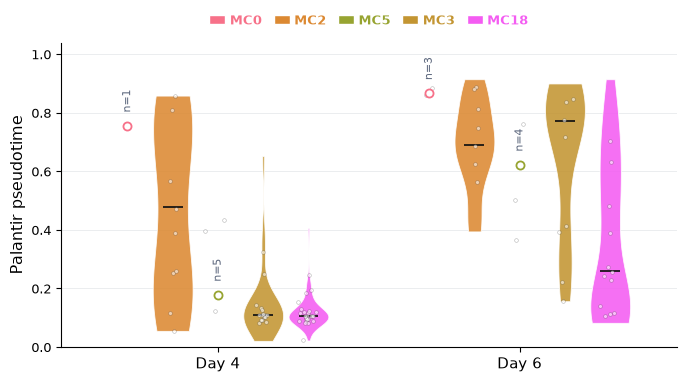

In [9]:
# Plot: Baso branch-compatible cell density along pseudotime
branch = "Baso"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.2, 4.35))
width = 0.15
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - 2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.04)
ax.set_ylabel("Palantir pseudotime", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_baso_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
plt.show()

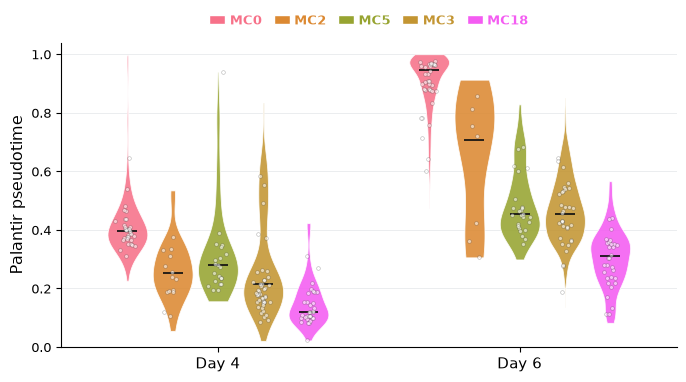

In [10]:
# Plot: Neu branch-compatible cell density along pseudotime
branch = "Neu"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.2, 4.35))
width = 0.15
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - 2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.04)
ax.set_ylabel("Palantir pseudotime", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_neu_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
plt.show()

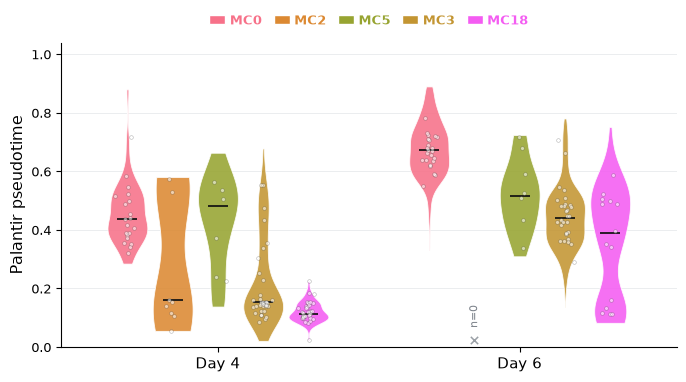

In [11]:
# Plot: Mono branch-compatible cell density along pseudotime
branch = "Mono"
mc_colors = {mc: MC_COLORS[mc] for mc in TARGET_MCS}
branch_cells = analysis_cells[analysis_cells[f"mask_{branch}"]].copy()
branch_cells = branch_cells[
    branch_cells["palantir_pseudotime"].notna()
]
branch_clone_medians = (
    branch_cells.groupby(["metaclone", "day", "LARRY_ID"], observed=True)[
        "palantir_pseudotime"
    ]
    .median()
    .rename("clone_median")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7.2, 4.35))
width = 0.15
rng = np.random.default_rng(20260901)
for day_position, day in enumerate(TARGET_DAYS):
    for mc_position, mc in enumerate(TARGET_MCS):
        x_position = day_position + (mc_position - 2) * width
        values = branch_cells.loc[
            (branch_cells["day"] == day) & (branch_cells["metaclone"] == mc),
            "palantir_pseudotime",
        ].to_numpy()
        clone_values = branch_clone_medians.loc[
            (branch_clone_medians["day"] == day)
            & (branch_clone_medians["metaclone"] == mc),
            "clone_median",
        ].to_numpy()
        if len(values) >= 8 and np.unique(values).size >= 2:
            violin = ax.violinplot(
                [values],
                positions=[x_position],
                widths=width * 0.88,
                showmedians=True,
                showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(mc_colors[mc])
                body.set_edgecolor("white")
                body.set_linewidth(0.6)
                body.set_alpha(0.88)
            violin["cmedians"].set_color("#111111")
            violin["cmedians"].set_linewidth(1.25)
        elif len(values) > 0:
            ax.scatter(
                [x_position],
                [float(np.median(values))],
                s=34,
                facecolors="white",
                edgecolors=mc_colors[mc],
                linewidths=1.3,
                zorder=4,
            )
            ax.text(
                x_position,
                min(1.01, float(np.median(values)) + 0.045),
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=7.6,
                color="#5C677D",
                rotation=90,
            )
        else:
            ax.scatter(
                [x_position], [0.025], marker="x", s=28,
                color="#9AA0A6", linewidths=1.1, zorder=4,
            )
            ax.text(
                x_position, 0.065, "n=0", ha="center", va="bottom",
                fontsize=7.6, color="#7C828A", rotation=90,
            )
        if len(clone_values):
            jitter = rng.normal(0, width * 0.09, size=len(clone_values))
            ax.scatter(
                np.full(len(clone_values), x_position) + jitter,
                clone_values,
                s=7,
                facecolors="white",
                edgecolors="#252525",
                linewidths=0.25,
                alpha=0.55,
                zorder=3,
            )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 4", "Day 6"], fontsize=11)
ax.set_xlim(-0.52, 1.52)
ax.set_ylim(0, 1.04)
ax.set_ylabel("Palantir pseudotime", fontsize=11.2)
ax.tick_params(axis="y", labelsize=9.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6E8EB", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=mc_colors[mc], edgecolor="white", label=f"MC{mc}")
    for mc in TARGET_MCS
]
legend = ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False,
    fontsize=9.5,
    ncol=len(TARGET_MCS),
    handlelength=1.2,
    handletextpad=0.35,
    columnspacing=0.9,
)
for label, mc in zip(legend.get_texts(), TARGET_MCS):
    label.set_color(mc_colors[mc])
    label.set_fontweight("bold")
fig.subplots_adjust(left=0.13, right=0.985, bottom=0.16, top=0.86)
branch_stem = FIGURE_DIR / "weinreb_multilineage_mono_branch_pseudotime"
fig.savefig(branch_stem.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.06)
fig.savefig(branch_stem.with_suffix(".png"), dpi=300, bbox_inches="tight", pad_inches=0.06)
plt.show()

In [12]:
# Programmatic claim audit: separate composition from overlapping branch occupancy
def pair_metric(table, metric, estimand, pair, day):
    subset = table[
        (table["estimand"] == estimand)
        & (table["day"] == day)
        & table.apply(
            lambda row: {int(row["mc_a"]), int(row["mc_b"])} == set(pair),
            axis=1,
        )
    ]
    assert len(subset) == 1
    return float(subset.iloc[0][metric])

claim_audit = pd.DataFrame(
    [
        {
            "claim_scope": "Fine-state composition",
            "comparison": "MC5 vs MC3",
            "estimand": "clone_balanced",
            "day4_distance": pair_metric(
                composition_distances, "jensen_shannon_distance",
                "clone_balanced", (5, 3), 4
            ),
            "day6_distance": pair_metric(
                composition_distances, "jensen_shannon_distance",
                "clone_balanced", (5, 3), 6
            ),
            "interpretation_rule": "larger distance means more different",
        },
        {
            "claim_scope": "Baso/Neu/Mono overlapping branch occupancy",
            "comparison": "MC3 vs MC18",
            "estimand": "pooled_cells",
            "day4_distance": pair_metric(
                branch_pair_distances, "euclidean_branch_occupancy_distance",
                "pooled_cells", (3, 18), 4
            ),
            "day6_distance": pair_metric(
                branch_pair_distances, "euclidean_branch_occupancy_distance",
                "pooled_cells", (3, 18), 6
            ),
            "interpretation_rule": "smaller distance means more similar occupancy",
        },
        {
            "claim_scope": "Baso/Neu/Mono overlapping branch occupancy",
            "comparison": "MC5 vs MC3",
            "estimand": "pooled_cells",
            "day4_distance": pair_metric(
                branch_pair_distances, "euclidean_branch_occupancy_distance",
                "pooled_cells", (5, 3), 4
            ),
            "day6_distance": pair_metric(
                branch_pair_distances, "euclidean_branch_occupancy_distance",
                "pooled_cells", (5, 3), 6
            ),
            "interpretation_rule": "larger distance means more different occupancy",
        },
    ]
)
claim_audit["day6_minus_day4"] = (
    claim_audit["day6_distance"] - claim_audit["day4_distance"]
)
claim_audit.to_csv(TABLE_DIR / "claim_audit.csv", index=False)
display(claim_audit)

baso_range = (
    branch_occupancy[
        (branch_occupancy["estimand"] == "pooled_cells")
        & (branch_occupancy["branch"] == "Baso")
    ]
    .groupby("day", observed=True)["occupancy_fraction"]
    .agg(["min", "max"])
)
display(baso_range.rename(columns={"min": "minimum_Baso_occupancy", "max": "maximum_Baso_occupancy"}))

,claim_scope,comparison,estimand,day4_distance,day6_distance,interpretation_rule,day6_minus_day4
0,Fine-state composition,MC5 vs MC3,clone_balanced,0.408365,0.428881,larger distance means more different,0.020516
1,Baso/Neu/Mono overlapping branch occupancy,MC3 vs MC18,pooled_cells,0.414625,0.174194,smaller distance means more similar occupancy,-0.240431
2,Baso/Neu/Mono overlapping branch occupancy,MC5 vs MC3,pooled_cells,0.250036,0.361774,larger distance means more different occupancy,0.111739


,minimum_Baso_occupancy,maximum_Baso_occupancy
day,,
4,0.002558,0.465909
6,0.003856,0.500000


In [13]:
# Reproducible output manifest with hashes
output_files = sorted(
    [
        path
        for folder in (FIGURE_DIR, TABLE_DIR)
        for path in folder.iterdir()
        if path.is_file()
    ]
)
manifest = pd.DataFrame(
    [
        {
            "path": str(path.relative_to(PROJECT_ROOT)),
            "bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
        for path in output_files
    ]
)
manifest.to_csv(REPORT_DIR / "output_manifest.csv", index=False)
print(f"Registered outputs: {len(manifest)}")
display(manifest)

Registered outputs: 99


,path,bytes,sha256
0,analysis_workspace/analyses/weinreb_multilineage_me...,132548,fc24c061a0ef38a0327ff4909dd07782f9ab9766a012b9...
1,analysis_workspace/analyses/weinreb_multilineage_me...,62069,508e97bc1d04b564334d2910fedf467d1f67d3cb1ecfbc...
2,analysis_workspace/analyses/weinreb_multilineage_me...,96905,ca74a0343675fa28ae576dec59ece74d59ca70303c7eb6...
3,analysis_workspace/analyses/weinreb_multilineage_me...,74146,7ebc56e50a89a13832fc7c09fe9382462ad141ee0f1337...
4,analysis_workspace/analyses/weinreb_multilineage_me...,194823,6c0172f8d9cbe7edc3d3632c6d6ed7b55618bf7c40386f...
...,...,...,...
94,analysis_workspace/analyses/weinreb_multilineage_me...,7930146,5c54d2a69a07c9430711449049f0abdb1c09e2992d9dd3...
95,analysis_workspace/analyses/weinreb_multilineage_me...,4922,dd48ea94ac24f0cb8e9ae29775a34e3f78e09b3ca7a3cf...
96,analysis_workspace/analyses/weinreb_multilineage_me...,4016,0145b17d0604d2b37b27f3f72662e9b0b1f20193fa6912...
97,analysis_workspace/analyses/weinreb_multilineage_me...,1620,941bb228f7e823a31b3b2f41ccd167df1daea1a30d6042...
